In [3]:
import psycopg2 as ps
import pandas as pd
import numpy as np

import requests
import json
import io

import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.cm as cm

from pylab import rcParams

from sklearn.metrics import ndcg_score, accuracy_score
import random
import time

import sys
sys.path.append('/home/roman/python/chgk/google_docs/')
sys.path.append('/home/roman/python/chgk/chgk_results/')
import ts_gd as gd
import chgk_api as cha



rcParams['figure.figsize'] = 8, 5

# настройки pandas, с которыми лучше почти всегда
pd.set_option('display.max_rows', 45000)
pd.set_option('display.max_columns', 50000)
pd.set_option('display.max_colwidth', 5000)

/home/roman/.local/lib/python3.10/site-packages/google/api_core/_python_version_support.py:266: FutureWarning: You are using a Python version (3.10.12) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2026-10-04). Please upgrade to the latest Python version, or at least Python 3.11, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


In [4]:
url = '1oKYT-rZwBScHsKAWi7Us7P4pIQjWNaiQj-6llkWXn4E'

In [47]:
df = gd.read(url, "Быллы_траспонированные!B2:L5000")
df.columns = ['id', 't1', 't2', 't3', 'dau', 'place', 'voice', 'swallow', 'izh', 'azh', 'level']

for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

In [49]:
df.describe()

,id,t1,t2,t3,dau,place,voice,swallow,izh,azh,level
count,64.000000,64.000000,64.000000,64.000000,64.000000,64.000000,64.000000,63.000000,61.000000,46.000000,60.000000
mean,32.500000,5.937500,6.046875,5.375000,7.281250,4.734375,6.500000,8.841270,7.786885,7.869565,8.716667
std,18.618987,2.623913,2.516168,2.848001,1.914595,2.656183,2.905933,1.952718,2.659040,2.777758,2.050975
min,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,2.000000,1.000000,0.000000,1.000000
25%,16.750000,4.000000,4.750000,3.000000,6.000000,3.000000,4.000000,8.000000,6.000000,6.000000,8.000000
50%,32.500000,6.000000,7.000000,6.000000,7.000000,4.500000,6.000000,10.000000,9.000000,9.000000,10.000000
75%,48.250000,8.000000,8.000000,7.250000,9.000000,7.000000,9.000000,10.000000,10.000000,10.000000,10.000000
max,64.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000


In [81]:
df[['t1', 't2', 't3', 'dau']].describe()

,t1,t2,t3,dau
count,64.000000,64.000000,64.000000,64.000000
mean,5.937500,6.046875,5.375000,7.281250
std,2.623913,2.516168,2.848001,1.914595
min,0.000000,0.000000,0.000000,1.000000
25%,4.000000,4.750000,3.000000,6.000000
50%,6.000000,7.000000,6.000000,7.000000
75%,8.000000,8.000000,7.250000,9.000000
max,10.000000,10.000000,10.000000,10.000000


(0.0, 10.0)

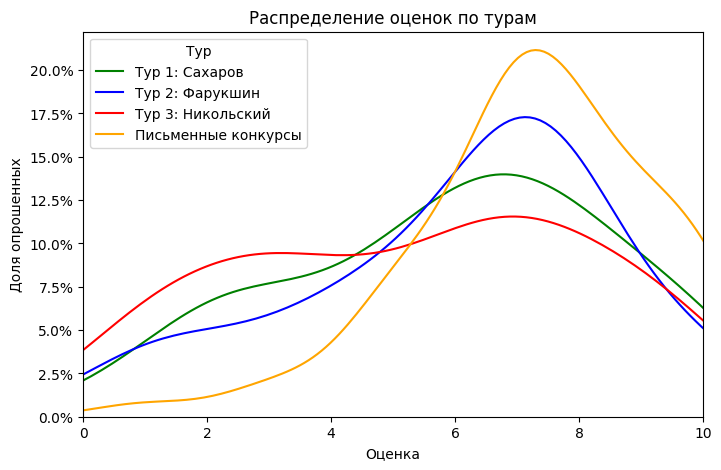

In [129]:
fig, ax = plt.subplots(figsize=(8, 5))
for col, color in zip(['t1', 't2', 't3', 'dau'], ['green', 'blue', 'red', 'orange']):
    sns.kdeplot(df[col], ax=ax, color=color, label=col, warn_singular=False)
ax.legend(title='series')
# replace from 't1', 't2', 't3' 'Сахаров', 'Фарукшин', 'Никльский' on legend 
ax.legend(title='Тур', labels=['Тур 1: Сахаров', 'Тур 2: Фарукшин', 'Тур 3: Никольский', 'Письменные конкурсы'])

ax.set_xlabel('score')
ax.set_title('Распределение оценок по турам')
ax.set_ylabel('Доля опрошенных')
ax.set_xlabel('Оценка')
# data format y axis percent
import matplotlib.ticker as mtick
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlim(0, 10)

In [82]:
t1_d = df[
    (df['t1'] >= 1) &
    (df['t1'] <= 3)
]['id'].nunique() / df['id'].nunique()

t1_u = df[
    (df['t1'] >= 6) &
    (df['t1'] <= 8)
]['id'].nunique() / df['id'].nunique()


t2_d = df[
    (df['t2'] >= 1) &
    (df['t2'] <= 3)
]['id'].nunique() / df['id'].nunique()

t2_u = df[
    (df['t2'] >= 6) &
    (df['t2'] <= 8)
]['id'].nunique() / df['id'].nunique()

t3_d = df[
    (df['t3'] >= 1) &
    (df['t3'] <= 3)
]['id'].nunique() / df['id'].nunique()
t3_u = df[
    (df['t3'] >= 6) &
    (df['t3'] <= 8)
]['id'].nunique() / df['id'].nunique()

dau_d = df[
    (df['dau'] >= 1) &
    (df['dau'] <= 3)
]['id'].nunique() / df['id'].nunique()
dau_u = df[
    (df['dau'] >= 6) &
    (df['dau'] <= 8)
]['id'].nunique() / df['id'].nunique()

print('t1_d', t1_d)
print('t1_u', t1_u)
print('t2_d', t2_d)
print('t2_u', t2_u)
print('t3_d', t3_d)
print('t3_u', t3_u)
print('dau_d', dau_d)
print('dau_u', dau_u)

t1_d 0.203125
t1_u 0.4375
t2_d 0.15625
t2_u 0.546875
t3_d 0.3125
t3_u 0.34375
dau_d 0.046875
dau_u 0.5625


In [78]:
df.sample(3)

,id,t1,t2,t3,dau,place,voice,swallow,izh,azh,level
43,44,10,10,7,6,1,2,10.0,10.0,10.0,10.0
60,61,5,5,5,9,6,3,6.0,6.0,6.0,9.0
47,48,7,8,6,7,3,10,10.0,7.0,7.0,7.0


(0.0, 10.0)

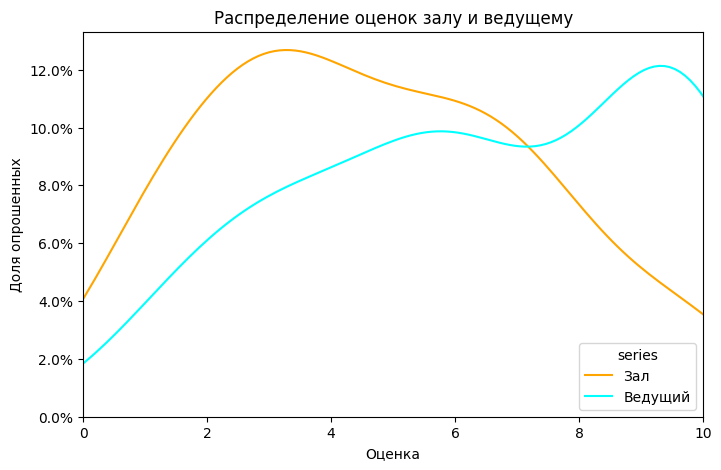

In [127]:
fig, ax = plt.subplots(figsize=(8, 5))
for col, color in zip(['place', 'voice'], ['orange', 'cyan']):
    sns.kdeplot(df[col], ax=ax, color=color, label=col, warn_singular=False)
ax.legend(title='series')
ax.legend(title='series', labels=['Зал', 'Ведущий'])

ax.set_xlabel('score')
ax.set_title('Распределение оценок залу и ведущему')
ax.set_ylabel('Доля опрошенных')
ax.set_xlabel('Оценка')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlim(0, 10)

(0.0, 10.0)

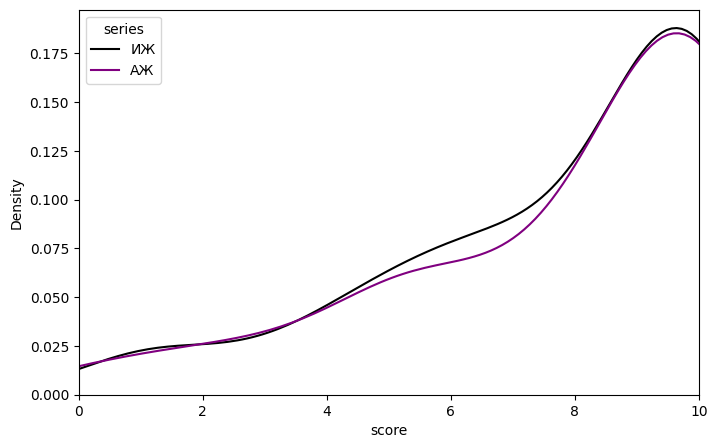

In [98]:
fig, ax = plt.subplots(figsize=(8, 5))
for col, color in zip(['izh', 'azh'], ['black', 'purple']):
    sns.kdeplot(df[col], ax=ax, color=color, label=col, warn_singular=False)
ax.legend(title='series')
ax.legend(title='series', labels=['ИЖ', 'АЖ'])

ax.set_xlabel('score')
# x axis from 0 to 10
ax.set_xlim(0, 10)

(0.0, 10.0)

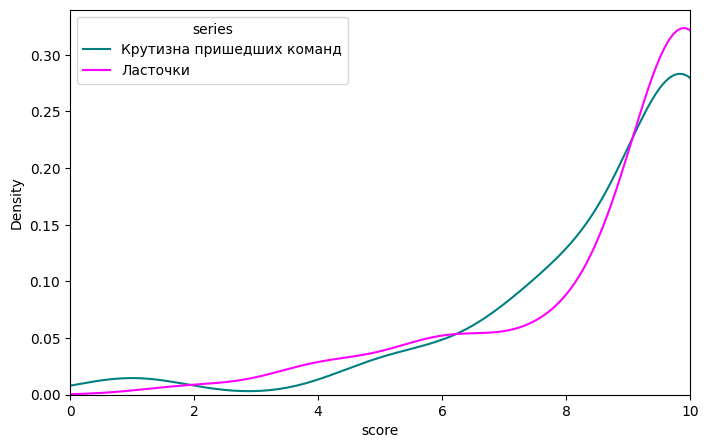

In [103]:
fig, ax = plt.subplots(figsize=(8, 5))
for col, color in zip(['level', 'swallow'], ['teal', 'magenta']):
    sns.kdeplot(df[col], ax=ax, color=color, label=col, warn_singular=False)
ax.legend(title='series')
ax.legend(title='series', labels=['Крутизна пришедших команд', 'Ласточки'])

ax.set_xlabel('score')
# x axis from 0 to 10
ax.set_xlim(0, 10)

Text(0.5, 1.0, 'Корреляция между оценками')

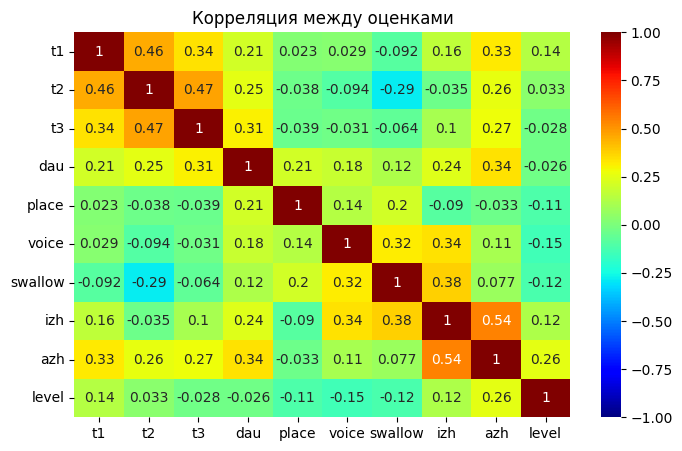

In [128]:
sns.heatmap(
    df[[
        't1', 't2', 't3', 'dau', 
        'place', 'voice', 'swallow', 
        'izh', 'azh', 'level'
        ]].corr(), 
        annot=True, 
        cmap='jet',
        center=0,
        vmin=-1,
        vmax=1,
        )
plt.title('Корреляция между оценками')

/tmp/ipykernel_64124/1385222171.py:1: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(


<Axes: xlabel='izh', ylabel='azh'>

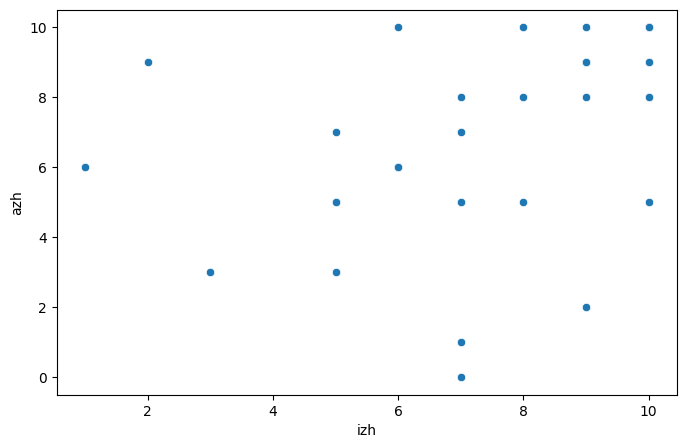

In [118]:
sns.scatterplot(
    x='izh',
    y='azh',
    data=df,
    palette='jet'
)

In [119]:
df.sample(3)

,id,t1,t2,t3,dau,place,voice,swallow,izh,azh,level
59,60,3,3,3,8,3,3,10.0,9.0,9.0,10.0
62,63,4,4,4,5,4,2,8.0,7.0,8.0,8.0
27,28,3,3,7,5,1,3,8.0,9.0,NaN,9.0
